# Savings Diagnostics — P2P Market

Investigates why one prosumer shows negative savings d_i < 0.

**Two questions answered here:**
1. Is the no-trade baseline computed consistently with the trading solve?
2. Does the negative saving disappear when regularisation costs (c_P, c_Q) are excluded?

All solves use `centralized()` so results are exact (no ADMM residual noise).

## 1  Setup

In [1]:
import sys, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Point to your project root if running from a different directory
# sys.path.insert(0, '/path/to/p2p-energy-trading-illustrative')

from scenarios import make_scenario, prosumer_summary
from algo_central import centralized
from metrics import no_trade_costs, savings

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

## 2  Build scenario

In [2]:
SEASON = 'winter'
data   = make_scenario(SEASON, seed=42, resolution_h=0.5)

N  = len(data['demand'])
T  = len(data['buy_price'])
dt = data['dt']
names = data['prosumer_names']

print(prosumer_summary().to_string())
print(f"\nT={T}, dt={dt}h, N={N}")
print(f"c_P={data.get('p_cost',0.):.2e}  c_Q={data.get('q_cost',0.):.2e}")
print(f"trade_fee={data['trade_fee']:.4f} EUR/kWh")

Building winter scenario (T=48, dt=0.5h, resolution=30min)...
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=48, dt=0.5h, max_demand=6.3 kW
                            Type Demand  Peak kW           PV            BESS             HP                   EV
Prosumer                                                                                                         
P1 (bus 5)        Residential ++   H0-B        8  PV5 12.0kWp   15.0kWh/7.0kW  random 10.0kW   HLS_A_11.0 60.0kWh
P2 (bus 11)      Office building   G4-B       25  PV1 30.0kWp  20.0kWh/10.0kW              —  APLS_A_11.0 40.0kWh
P3 (bus 17)  Residential HP only   H0-G        5            —               —   random 8.0kW                    —
P4 (bus 32)  Residential P

## 3  Centralized solve — with trading

In [3]:
result_trade = centralized(data)
print("Trading costs (EUR):")
for i, c in enumerate(result_trade['costs']):
    print(f"  P{i+1} ({names[i]}): {c:.4f}")

Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
Trading costs (EUR):
  P1 (Residential ++): 7.4449
  P2 (Office building): 37.1327
  P3 (Residential HP only): 3.2740
  P4 (Residential PV only): 10.7492


## 4  No-trade baselines

Two methods compared:
- **Method A** — `no_trade_costs()` from `metrics.py`: runs N separate single-agent Gurobi solves
- **Method B** — `centralized()` with `edges=[]`: same solver as the trading case, just no trade variables

They should give identical results. Any difference points to a formulation inconsistency.

In [4]:
# Method A — current implementation in metrics.py
J_nt_A = no_trade_costs(data)

# Method B — centralized with edges removed
data_nt = {**data, 'edges': []}
result_nt_B = centralized(data_nt)
J_nt_B = result_nt_B['costs']

df_nt = pd.DataFrame({
    'No-trade (metrics.py)': J_nt_A,
    'No-trade (centralized, edges=[])': J_nt_B,
    'Difference': J_nt_B - J_nt_A,
}, index=[f'P{i+1} ({names[i]})' for i in range(N)])

print(df_nt.to_string())
print(f"\nMax absolute difference: {np.max(np.abs(J_nt_B - J_nt_A)):.2e} EUR")

  P1 no-trade cost: 6.5239 EUR
  P2 no-trade cost: 38.2949 EUR
  P3 no-trade cost: 3.3480 EUR
  P4 no-trade cost: 11.0764 EUR
                          No-trade (metrics.py)  No-trade (centralized, edges=[])  Difference
P1 (Residential ++)                      6.5239                            6.5239     -0.0000
P2 (Office building)                    38.2949                           38.2949     -0.0000
P3 (Residential HP only)                 3.3480                            3.3480      0.0000
P4 (Residential PV only)                11.0764                           11.0764      0.0000

Max absolute difference: 1.61e-08 EUR


## 5  Cost decomposition

Split each prosumer's cost into:
- **Economic** — grid tariffs, P2P revenue, device cycling costs, trade fee
- **Regularisation** — c_P and c_Q quadratic penalty terms (numerics only, not economic)

The savings metric d_i = (J_nt - J) / J_nt should ideally use economic costs only.
Including regularisation costs in savings is misleading because c_P penalises trade
flows, making traders look worse than non-traders on a regularisation basis alone.

In [5]:
def decompose_costs(result, data):
    """Return (econ_costs, reg_costs) arrays of shape (N,)."""
    N   = len(data['demand'])
    T   = len(data['buy_price'])
    dt  = data['dt']
    bp  = np.array(data['buy_price'])
    sp  = np.array(data['sell_price'])
    pp  = np.array(data['p2p_price'])
    fee = data['trade_fee']
    c_b = data['battery_cost']
    c_ev = data.get('ev_cost', 0.)
    c_hp = data.get('hp_cost', 0.)
    c_q  = data.get('q_cost',  0.)
    c_p  = data.get('p_cost',  0.)

    econ = np.zeros(N)
    reg  = np.zeros(N)

    peers_of = {i: [b if a==i else a for a,b in data['edges'] if i in (a,b)]
                for i in range(N)}

    for i in range(N):
        buy  = result['buy'][i]
        sell = result['sell'][i]
        ch   = result['charge'][i]
        di   = result['discharge'][i]
        ec   = result['ev_charge'][i]
        ed   = result['ev_discharge'][i]
        hp   = result['hp_power'][i]
        qb   = result['q_batt'][i]
        qp   = result['q_pv'][i]
        qe   = result['ev_q_charger'][i]

        net_trade = np.array([
            sum(result['trades'].get((i,j,t), 0.) for j in peers_of[i])
            for t in range(T)])
        abs_trade = np.array([
            sum(abs(result['trades'].get((i,j,t), 0.)) for j in peers_of[i])
            for t in range(T)])
        trade_sq = np.array([
            sum(result['trades'].get((i,j,t), 0.)**2 for j in peers_of[i])
            for t in range(T)])

        econ[i] = dt * np.sum(
            bp*buy - sp*sell - pp*net_trade
            + c_b*(ch+di) + c_ev*(ec+ed) + c_hp*hp
        ) + dt * fee * np.sum(abs_trade)

        reg[i] = dt * np.sum(
            c_q*(qb**2 + qp**2 + qe**2)
            + c_p*(ch**2 + di**2 + ec**2 + ed**2 + trade_sq)
        )

    return econ, reg


econ_trade, reg_trade = decompose_costs(result_trade, data)
econ_nt,    reg_nt    = decompose_costs(result_nt_B, data)

print("Sanity check — decomposed vs reported costs:")
for i in range(N):
    reported = result_trade['costs'][i]
    recon    = econ_trade[i] + reg_trade[i]
    print(f"  P{i+1}: reported={reported:.4f}  econ+reg={recon:.4f}  diff={recon-reported:.2e}")

Sanity check — decomposed vs reported costs:
  P1: reported=7.4449  econ+reg=7.4449  diff=-1.22e-10
  P2: reported=37.1327  econ+reg=37.1327  diff=-1.30e-10
  P3: reported=3.2740  econ+reg=3.2740  diff=-1.33e-10
  P4: reported=10.7492  econ+reg=10.7492  diff=-1.25e-10


## 6  Savings — full cost vs economic cost only

d_full   = (J_nt_full   - J_trade_full)   / J_nt_full    ← what metrics.py computes today
d_econ   = (J_nt_econ   - J_trade_econ)   / J_nt_econ    ← economic costs only
d_reg    = contribution of regularisation to the difference

In [6]:
# Use Method B baseline (same solver) for fairness
J_nt_full = J_nt_B                              # total cost at no-trade
J_nt_econ = econ_nt                             # economic cost at no-trade

d_full = (J_nt_full  - result_trade['costs']) / np.where(np.abs(J_nt_full)  > 1e-9, J_nt_full,  1.)
d_econ = (J_nt_econ  - econ_trade)             / np.where(np.abs(J_nt_econ) > 1e-9, J_nt_econ,  1.)
d_reg_contribution = d_full - d_econ

df_savings = pd.DataFrame({
    'J_nt  (full)':    J_nt_full,
    'J_nt  (econ)':    J_nt_econ,
    'J_nt  (reg)':     reg_nt,
    'J     (full)':    result_trade['costs'],
    'J     (econ)':    econ_trade,
    'J     (reg)':     reg_trade,
    'd_full':          d_full,
    'd_econ':          d_econ,
    'd_reg_contrib':   d_reg_contribution,
}, index=[f'P{i+1} ({names[i]})' for i in range(N)])

print(df_savings.to_string())
print()
print(f"d_full  range: [{d_full.min():.4f}, {d_full.max():.4f}]")
print(f"d_econ  range: [{d_econ.min():.4f}, {d_econ.max():.4f}]")

                          J_nt  (full)  J_nt  (econ)  J_nt  (reg)  J     (full)  J     (econ)  J     (reg)  d_full  d_econ  d_reg_contrib
P1 (Residential ++)             6.5239        6.4686       0.0553        7.4449        7.3377       0.1073 -0.1412 -0.1343        -0.0068
P2 (Office building)           38.2949       38.0269       0.2680       37.1327       36.9126       0.2201  0.0303  0.0293         0.0010
P3 (Residential HP only)        3.3480        3.3480       0.0000        3.2740        3.2736       0.0005  0.0221  0.0222        -0.0001
P4 (Residential PV only)       11.0764       11.0328       0.0436       10.7492       10.6991       0.0501  0.0295  0.0302        -0.0007

d_full  range: [-0.1412, 0.0303]
d_econ  range: [-0.1343, 0.0302]


## 7  Savings bar chart

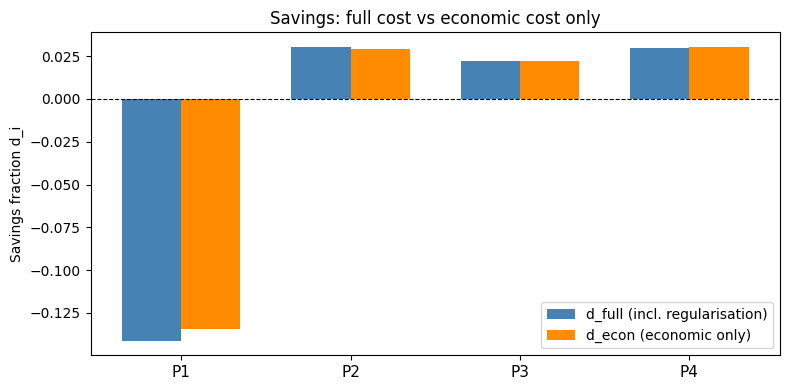

Saved: savings_comparison.pdf


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
x  = np.arange(N)
w  = 0.35
ax.bar(x - w/2, d_full, w, label='d_full (incl. regularisation)', color='steelblue')
ax.bar(x + w/2, d_econ, w, label='d_econ (economic only)',        color='darkorange')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels([f'P{i+1}' for i in range(N)], fontsize=11)
ax.set_ylabel('Savings fraction d_i')
ax.set_title('Savings: full cost vs economic cost only')
ax.legend()
plt.tight_layout()
plt.savefig('savings_comparison.pdf', bbox_inches='tight')
plt.show()
print("Saved: savings_comparison.pdf")

## 8  Per-prosumer cost breakdown — trading case

In [8]:
def cost_breakdown(result, data, label=''):
    """Return a DataFrame with one column per cost component per prosumer."""
    N   = len(data['demand'])
    T   = len(data['buy_price'])
    dt  = data['dt']
    bp  = np.array(data['buy_price'])
    sp  = np.array(data['sell_price'])
    pp  = np.array(data['p2p_price'])
    fee = data['trade_fee']
    c_b = data['battery_cost']
    c_ev = data.get('ev_cost', 0.)
    c_hp = data.get('hp_cost', 0.)
    c_q  = data.get('q_cost',  0.)
    c_p  = data.get('p_cost',  0.)

    peers_of = {i: [b if a==i else a for a,b in data['edges'] if i in (a,b)]
                for i in range(N)}

    rows = []
    for i in range(N):
        buy  = result['buy'][i];   sell = result['sell'][i]
        ch   = result['charge'][i]; di   = result['discharge'][i]
        ec   = result['ev_charge'][i]; ed = result['ev_discharge'][i]
        hp   = result['hp_power'][i]
        qb   = result['q_batt'][i]; qp = result['q_pv'][i]; qe = result['ev_q_charger'][i]

        net_trade = np.array([sum(result['trades'].get((i,j,t),0.) for j in peers_of[i]) for t in range(T)])
        abs_trade = np.array([sum(abs(result['trades'].get((i,j,t),0.)) for j in peers_of[i]) for t in range(T)])
        trade_sq  = np.array([sum(result['trades'].get((i,j,t),0.)**2 for j in peers_of[i]) for t in range(T)])

        rows.append({
            'Grid buy':    dt * float(np.sum(bp * buy)),
            'Grid sell':   -dt * float(np.sum(sp * sell)),
            'P2P revenue': -dt * float(np.sum(pp * net_trade)),
            'Trade fee':   dt * fee * float(np.sum(abs_trade)),
            'BESS cycling': dt * c_b * float(np.sum(ch + di)),
            'EV cycling':  dt * c_ev * float(np.sum(ec + ed)),
            'HP cost':     dt * c_hp * float(np.sum(hp)),
            'Reg (c_Q)':   dt * c_q * float(np.sum(qb**2 + qp**2 + qe**2)),
            'Reg (c_P)':   dt * c_p * float(np.sum(ch**2 + di**2 + ec**2 + ed**2 + trade_sq)),
            'TOTAL':       float(result['costs'][i]),
        })

    df = pd.DataFrame(rows, index=[f'P{i+1} ({names[i]})' for i in range(N)])
    return df

print("=== TRADING ===")
print(cost_breakdown(result_trade, data).to_string())
print()
print("=== NO TRADE (centralized, edges=[]) ===")
print(cost_breakdown(result_nt_B, data_nt).to_string())

=== TRADING ===
                          Grid buy  Grid sell  P2P revenue  Trade fee  BESS cycling  EV cycling  HP cost  Reg (c_Q)  Reg (c_P)   TOTAL
P1 (Residential ++)         9.3067    -0.0000      -2.1869     0.0109        0.1756      0.0313   0.0000     0.0000     0.1073  7.4449
P2 (Office building)       34.8856    -0.0000       1.6605     0.0083        0.2903      0.0679   0.0000     0.0000     0.2201 37.1327
P3 (Residential HP only)    3.1710    -0.0000       0.1012     0.0014        0.0000      0.0000   0.0000     0.0000     0.0005  3.2740
P4 (Residential PV only)   10.1228    -0.0000       0.4252     0.0041        0.1470      0.0000   0.0000     0.0000     0.0501 10.7492

=== NO TRADE (centralized, edges=[]) ===
                          Grid buy  Grid sell  P2P revenue  Trade fee  BESS cycling  EV cycling  HP cost  Reg (c_Q)  Reg (c_P)   TOTAL
P1 (Residential ++)         6.3028    -0.0000      -0.0000     0.0000        0.1345      0.0313   0.0000     0.0000     0.0553  6.52

## 9  Diagnosis

In [9]:
print("=" * 60)
print("DIAGNOSIS")
print("=" * 60)

for i in range(N):
    print(f"\nP{i+1} ({names[i]})")
    print(f"  d_full = {d_full[i]:+.4f}   d_econ = {d_econ[i]:+.4f}")
    print(f"  reg contribution to savings: {d_reg_contribution[i]:+.4f}")

    if d_full[i] < 0 and d_econ[i] >= 0:
        print(f"  *** REGULARISATION ARTEFACT — economically rational but "
              f"penalised by c_P/c_Q (c_P={data.get('p_cost',0.):.1e}, "
              f"c_Q={data.get('q_cost',0.):.1e})")
    elif d_full[i] < 0 and d_econ[i] < 0:
        print(f"  *** GENUINE NEGATIVE SAVING — prosumer is economically "
              f"worse off trading; market design / pricing issue")
    else:
        print(f"  OK — positive savings under both cost definitions")

DIAGNOSIS

P1 (Residential ++)
  d_full = -0.1412   d_econ = -0.1343
  reg contribution to savings: -0.0068
  *** GENUINE NEGATIVE SAVING — prosumer is economically worse off trading; market design / pricing issue

P2 (Office building)
  d_full = +0.0303   d_econ = +0.0293
  reg contribution to savings: +0.0010
  OK — positive savings under both cost definitions

P3 (Residential HP only)
  d_full = +0.0221   d_econ = +0.0222
  reg contribution to savings: -0.0001
  OK — positive savings under both cost definitions

P4 (Residential PV only)
  d_full = +0.0295   d_econ = +0.0302
  reg contribution to savings: -0.0007
  OK — positive savings under both cost definitions
